In [1]:
import sys; print(sys.executable)

/home/linux1/tp/bin/python3


In [1]:
# Platform evidence: this notebook runs on IBM LinuxONE (IBM z17, Telum II) with the on-chip AI accelerator visible.
import platform, os, sys, subprocess, ctypes, importlib
sh = lambda c: subprocess.run(c, shell=True, capture_output=True, text=True).stdout.strip()
print(platform.machine(), "|", platform.platform(), "| Python", sys.version.split()[0], "| CPUs:", os.cpu_count())
print(sh("lscpu | grep -E 'Machine type|Vendor ID|Hypervisor:'"))
print("NNPA flag in /proc/cpuinfo:", "nnpa" in sh("grep -m1 '^features' /proc/cpuinfo"))
try:
    z = ctypes.CDLL("libzdnn.so.0"); z.zdnn_init(); z.zdnn_is_nnpa_installed.restype = ctypes.c_bool
    print("zDNN reports NNPA installed:", z.zdnn_is_nnpa_installed())
except OSError:
    print("zDNN not installed (sudo apt install libzdnn0)")
print(sh("free -h | head -2"))
for m in ["numpy", "pandas", "sklearn", "networkx", "matplotlib", "flask"]:
    print(f"{m:11}", getattr(importlib.import_module(m), "__version__", "?"))

s390x | Linux-6.8.0-147-generic-s390x-with-glibc2.39 | Python 3.12.3 | CPUs: 3
Vendor ID:                               IBM/S390
Machine type:                            9175
Hypervisor:                              z/VM 7.3.0
NNPA flag in /proc/cpuinfo: True
zDNN reports NNPA installed: True
total        used        free      shared  buff/cache   available
Mem:           7.8Gi       1.8Gi       4.7Gi        25Mi       1.5Gi       6.1Gi
numpy       1.26.4
pandas      2.1.4
sklearn     1.4.1.post1
networkx    2.8.8
matplotlib  3.6.3
flask       3.1.3


/tmp/ipykernel_55291/1257198804.py:14: DeprecationWarning: The '__version__' attribute is deprecated and will be removed in Flask 3.2. Use feature detection or 'importlib.metadata.version("flask")' instead.
  print(f"{m:11}", getattr(importlib.import_module(m), "__version__", "?"))


In [3]:
pip install --prefer-binary numpy pandas scikit-learn networkx xgboost pyarrow

  Using cached xgboost-3.4.1.tar.gz (1.2 MB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached pyarrow-26.0.0.tar.gz (1.2 MB)
  Installing build dependencies ... error
  error: subprocess-exited-with-error
  
  × installing build dependencies for pyarrow did not run successfully.
  │ exit code: 1
  ╰─> [493 lines of output]
      Ignoring libcst: markers 'python_version >= "3.15"' don't match your environment
        Using cached scikit_build_core-1.1.1-py3-none-any.whl.metadata (19 kB)
        Using cached cython-3.3.0-py3-none-any.whl.metadata (28 kB)
        Using cached libcst-1.9.0.tar.gz (914 kB)
        Installing build dependencies: started
        Installing build dependencies: finished with status 'done'
        Getting requirements to build wheel: started
        Getting requirements to build wheel: finished with status 'done'
       

In [4]:
import platform, os, sys, importlib, subprocess
sh = lambda c: subprocess.run(c, shell=True, capture_output=True, text=True).stdout
print(sys.executable)
print(platform.machine(), "|", platform.platform(), "|", sys.version.split()[0])
print("CPUs:", os.cpu_count())
print(sh("free -h")); print(sh("df -h /"))
print(sh("grep -m1 '^features' /proc/cpuinfo"))
for m in ["numpy","pandas","scipy","sklearn","xgboost","networkx","matplotlib"]:
    try:
        mod = importlib.import_module(m); print(f"{m:11} {getattr(mod,'__version__','?'):10} {mod.__file__}")
    except Exception as e:
        print(f"{m:11} MISSING ({type(e).__name__}: {e})")

/home/linux1/tp/bin/python3
s390x | Linux-6.8.0-147-generic-s390x-with-glibc2.39 | 3.12.3
CPUs: 3
               total        used        free      shared  buff/cache   available
Mem:           7.8Gi       1.4Gi       6.2Gi        18Mi       375Mi       6.4Gi
Swap:          4.0Gi          0B       4.0Gi

Filesystem      Size  Used Avail Use% Mounted on
/dev/dasda1      50G  9.6G   38G  21% /

features	: esan3 zarch stfle msa ldisp eimm dfp edat etf3eh highgprs te vx vxd vxe gs vxe2 vxp sort dflt vxp2 nnpa sie 

numpy       1.26.4     /usr/lib/python3/dist-packages/numpy/__init__.py
pandas      2.1.4      /usr/lib/python3/dist-packages/pandas/__init__.py
scipy       1.11.4     /usr/lib/python3/dist-packages/scipy/__init__.py
sklearn     1.4.1.post1 /usr/lib/python3/dist-packages/sklearn/__init__.py
xgboost     MISSING (ModuleNotFoundError: No module named 'xgboost')
networkx    2.8.8      /usr/lib/python3/dist-packages/networkx/__init__.py
matplotlib  3.6.3      /usr/lib/python3/dist-pa

In [7]:
import glob, time, platform, numpy as np, pandas as pd

path = glob.glob("/home/linux1/trustpulse/data/PS_*.csv")[0]
t0 = time.time()
# Balance columns are excluded: PaySim cancels fraud transactions, so balances leak the label.
# isFlaggedFraud is the simulator's own rule output, not something a bank sees pre-payment.
df = pd.read_csv(path,
                 usecols=["step", "type", "amount", "nameOrig", "nameDest", "isFraud"],
                 dtype={"step": "int16", "type": "category", "amount": "float64",
                        "nameOrig": "category", "nameDest": "category", "isFraud": "int8"})
df["orig_id"] = df.nameOrig.cat.codes.astype("int32")
df["dest_id"] = df.nameDest.cat.codes.astype("int32")
df["dest_is_merchant"] = df.nameDest.str.startswith("M").astype("int8")
n_orig_unique = df.orig_id.nunique()
df = df.drop(columns=["nameOrig", "nameDest"])

print(f"loaded {len(df):,} rows in {time.time()-t0:.1f}s | steps {df.step.min()}-{df.step.max()}")
print(f"fraud rate {df.isFraud.mean():.5f} | unique senders {n_orig_unique:,}")
print(df.groupby("type", observed=True).isFraud.agg(["size", "sum"]))

loaded 6,362,620 rows in 43.0s | steps 1-743
fraud rate 0.00129 | unique senders 6,353,307
             size   sum
type                   
CASH_IN   1399284     0
CASH_OUT  2237500  4116
DEBIT       41432     0
PAYMENT   2151495     0
TRANSFER   532909  4097


In [8]:
df["log_amount"] = np.log1p(df.amount)
df["hour"] = (df.step % 24).astype("int8")
df["type_code"] = df.type.cat.codes.astype("int8")

# Per-destination history, aggregated per step, then shifted so a row only sees prior steps.
g = df.groupby(["dest_id", "step"]).agg(n=("amount", "size"), amt=("amount", "sum")).reset_index()
gg = g.groupby("dest_id")
g["dest_prev_n"] = gg["n"].cumsum() - g["n"]
g["dest_prev_amt"] = gg["amt"].cumsum() - g["amt"]
g["dest_last_step"] = gg["step"].shift(1)
df = df.merge(g[["dest_id", "step", "dest_prev_n", "dest_prev_amt", "dest_last_step"]],
              on=["dest_id", "step"], how="left")
del g, gg

df["dest_prev_mean"] = (df.dest_prev_amt / df.dest_prev_n).fillna(0)
df["dest_gap"] = (df.step - df.dest_last_step).fillna(-1)
df["dest_is_new"] = (df.dest_prev_n == 0).astype("int8")
df["amt_vs_dest_mean"] = df.amount / (df.dest_prev_mean + 1)

FEATURES = ["log_amount", "hour", "type_code", "dest_is_merchant", "dest_prev_n",
            "dest_prev_amt", "dest_prev_mean", "dest_gap", "dest_is_new", "amt_vs_dest_mean"]
df[FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
log_amount,6362620.0,1.084087e+01,1.814509e+00,0.0,9.502306,11.223548,1.224876e+01,1.834213e+01
hour,6362620.0,1.532145e+01,4.321799e+00,0.0,12.000000,16.000000,1.900000e+01,2.300000e+01
type_code,6362620.0,1.714150e+00,1.350117e+00,0.0,1.000000,1.000000,3.000000e+00,4.000000e+00
dest_is_merchant,6362620.0,3.381461e-01,4.730786e-01,0.0,0.000000,0.000000,1.000000e+00,1.000000e+00
dest_prev_n,6362620.0,5.027121e+00,7.819176e+00,0.0,0.000000,1.000000,7.000000e+00,1.120000e+02
dest_prev_amt,6362620.0,1.333362e+06,3.161797e+06,0.0,0.000000,206752.010000,1.516806e+06,3.572774e+08
dest_prev_mean,6362620.0,1.411620e+05,2.992506e+05,0.0,0.000000,99061.820000,2.155155e+05,3.992057e+07
dest_gap,6362620.0,1.742200e+01,4.064338e+01,-1.0,-1.000000,1.000000,2.000000e+01,6.810000e+02
dest_is_new,6362620.0,4.353400e-01,4.958015e-01,0.0,0.000000,0.000000,1.000000e+00,1.000000e+00
amt_vs_dest_mean,6362620.0,2.958355e+04,2.096905e+05,0.0,0.677383,2.686313,1.035311e+04,3.223490e+07


In [9]:
TRAIN_END, VAL_END = 400, 550
tr = df[df.step <= TRAIN_END]
va = df[(df.step > TRAIN_END) & (df.step <= VAL_END)]
te = df[df.step > VAL_END]
for name, d in [("train", tr), ("val", va), ("test", te)]:
    print(f"{name:5} rows {len(d):>9,} fraud {d.isFraud.sum():>5} rate {d.isFraud.mean():.4f}")

# Downsample legit rows in train for speed on 3 vCPUs; ranking metrics are unaffected.
rng = np.random.default_rng(42)
trs = tr[(tr.isFraud == 1) | (rng.random(len(tr)) < 0.2)]
print("train sample", len(trs), "fraud", trs.isFraud.sum())

train rows 5,787,030 fraud  4477 rate 0.0008
val   rows   378,989 fraud  1588 rate 0.0042
test  rows   196,601 fraud  2148 rate 0.0109
train sample 1160887 fraud 4477


In [10]:
try:
    import xgboost as xgb
    spw = (trs.isFraud == 0).sum() / trs.isFraud.sum()
    model = xgb.XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.1,
                              tree_method="hist", n_jobs=3, scale_pos_weight=spw,
                              eval_metric="aucpr", random_state=42)
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    model = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, max_leaf_nodes=63,
                                           early_stopping=False, class_weight="balanced",
                                           random_state=42)
t0 = time.time()
model.fit(trs[FEATURES], trs.isFraud)
print(type(model).__name__, f"trained in {time.time()-t0:.1f}s")

HistGradientBoostingClassifier trained in 15.6s


In [11]:
from sklearn.metrics import average_precision_score, roc_auc_score

def evaluate(d, name, budget=0.005):
    p = model.predict_proba(d[FEATURES])[:, 1]
    y = d.isFraud.values
    top = np.argsort(-p)[:max(1, int(budget * len(d)))]
    print(f"{name}: PR-AUC {average_precision_score(y, p):.4f} | ROC-AUC {roc_auc_score(y, p):.4f} | "
          f"recall@{budget:.1%} alerts {y[top].sum()/y.sum():.3f} | precision {y[top].mean():.3f}")
    return p

p_va = evaluate(va, "val")
p_te = evaluate(te, "test")

x1 = te[FEATURES].iloc[:1]
t = time.perf_counter()
for _ in range(200):
    model.predict_proba(x1)
single_ms = (time.perf_counter() - t) / 200 * 1000
xb = te[FEATURES].iloc[:10000]
t = time.perf_counter(); model.predict_proba(xb)
batch_us = (time.perf_counter() - t) / 10000 * 1e6
print(f"latency on {platform.machine()}: single txn {single_ms:.2f} ms | batch {batch_us:.1f} µs/txn")

val: PR-AUC 0.4286 | ROC-AUC 0.9663 | recall@0.5% alerts 0.467 | precision 0.392
test: PR-AUC 0.5589 | ROC-AUC 0.9664 | recall@0.5% alerts 0.356 | precision 0.777
latency on s390x: single txn 2.60 ms | batch 5.7 µs/txn


In [12]:
import joblib, os
os.makedirs("/home/linux1/trustpulse/artifacts", exist_ok=True)
joblib.dump(model, "/home/linux1/trustpulse/artifacts/baseline.joblib")
df.to_pickle("/home/linux1/trustpulse/artifacts/paysim_features.pkl")

## Part 2: Network-aware engine on IBM AML (HI-Small)

In [13]:
import time, numpy as np, pandas as pd
DATA = "/home/linux1/trustpulse/data"
COLS = ["ts", "from_bank", "from_acct", "to_bank", "to_acct", "amt_recv", "cur_recv",
        "amt_paid", "cur_paid", "fmt", "is_laundering"]
DTYPES = {"from_bank": str, "from_acct": str, "to_bank": str, "to_acct": str,
          "cur_recv": "category", "cur_paid": "category", "fmt": "category", "is_laundering": "int8"}

t0 = time.time()
aml = pd.read_csv(f"{DATA}/HI-Small_Trans.csv", header=0, names=COLS, dtype=DTYPES)
aml["ts"] = pd.to_datetime(aml.ts, format="%Y/%m/%d %H:%M")

# One shared integer id per (bank, account) so senders and receivers live in the same graph.
src = aml.from_bank + "_" + aml.from_acct
dst = aml.to_bank + "_" + aml.to_acct
codes, uniques = pd.factorize(pd.concat([src, dst], ignore_index=True))
aml["src"] = codes[:len(aml)].astype("int32")
aml["dst"] = codes[len(aml):].astype("int32")
del src, dst, codes

aml = aml.sort_values("ts", kind="stable").reset_index(drop=True)
aml["txn_id"] = np.arange(len(aml), dtype="int32")

print(f"{len(aml):,} rows in {time.time()-t0:.1f}s | {aml.ts.min()} to {aml.ts.max()}")
print(f"accounts {len(uniques):,} | laundering rate {aml.is_laundering.mean():.5f} | "
      f"self-transfers {(aml.src == aml.dst).mean():.3f}")
print(aml.groupby("fmt", observed=True).is_laundering.agg(["size", "sum"]))

5,078,345 rows in 14.7s | 2022-09-01 00:00:00 to 2022-09-18 16:18:00
accounts 515,088 | laundering rate 0.00102 | self-transfers 0.116
                 size   sum
fmt                        
ACH            600797  4483
Bitcoin        146091    56
Cash           490891   108
Cheque        1864331   324
Credit Card   1323324   206
Reinvestment   481056     0
Wire           171855     0


In [14]:
rows, pid, ptype = [], -1, None
with open(f"{DATA}/HI-Small_Patterns.txt") as f:
    for line in f:
        line = line.strip()
        if line.startswith("BEGIN"):
            pid += 1
            ptype = line.split("-", 1)[1].split(":")[0].strip()
        elif line and not line.startswith("END"):
            rows.append(line.split(",") + [pid, ptype])

pat = pd.DataFrame(rows, columns=COLS + ["pattern_id", "pattern_type"])
pat["ts"] = pd.to_datetime(pat.ts, format="%Y/%m/%d %H:%M")
pat["amt_paid"] = pat.amt_paid.astype(float)
KEY = ["ts", "from_bank", "from_acct", "to_bank", "to_acct", "amt_paid"]
pat = pat.drop_duplicates(KEY)[KEY + ["pattern_id", "pattern_type"]]

aml = aml.merge(pat, on=KEY, how="left")
aml["pattern_id"] = aml.pattern_id.fillna(-1).astype("int32")

lab = aml.is_laundering == 1
print(f"patterns {pid+1:,} | laundering txns in a pattern: {(lab & (aml.pattern_id >= 0)).sum():,} "
      f"of {lab.sum():,} | pattern txns not labelled: {(~lab & (aml.pattern_id >= 0)).sum():,}")

ps = aml[aml.pattern_id >= 0].groupby("pattern_id").agg(
    ptype=("pattern_type", "first"), n=("txn_id", "size"), start=("ts", "min"), end=("ts", "max"))
ps["hours"] = (ps.end - ps.start).dt.total_seconds() / 3600
print(ps.groupby("ptype").agg(patterns=("n", "size"), txns_median=("n", "median"),
                              hours_median=("hours", "median"), hours_p90=("hours", lambda h: h.quantile(0.9))))

patterns 370 | laundering txns in a pattern: 3,209 of 5,177 | pattern txns not labelled: 0
                patterns  txns_median  hours_median   hours_p90
ptype                                                          
BIPARTITE             49          4.0     24.333333   43.123333
CYCLE                 54          4.0     71.883333   90.350000
FAN-IN                40          8.0     84.933333   94.696667
FAN-OUT               48          7.0     76.658333   94.708333
GATHER-SCATTER        51         14.0    150.816667  183.833333
RANDOM                41          3.0     46.000000   86.633333
SCATTER-GATHER        44         14.0     88.766667   95.495000
STACK                 43         10.0     73.316667  100.996667


In [15]:
daily = aml.groupby(aml.ts.dt.date).agg(txns=("txn_id", "size"), laundering=("is_laundering", "sum"))
daily["rate"] = daily.laundering / daily.txns
print(daily)
aml = aml.drop(columns=["from_acct", "to_acct"])
aml.to_pickle("/home/linux1/trustpulse/artifacts/aml_hi_small.pkl")

               txns  laundering      rate
ts                                       
2022-09-01  1114921         322  0.000289
2022-09-02   754449         408  0.000541
2022-09-03   207382         391  0.001885
2022-09-04   207430         407  0.001962
2022-09-05   482650         471  0.000976
2022-09-06   482089         531  0.001101
2022-09-07   482751         497  0.001030
2022-09-08   482773         539  0.001116
2022-09-09   654467         514  0.000785
2022-09-10   208325         442  0.002122
2022-09-11      396         232  0.585859
2022-09-12      281         170  0.604982
2022-09-13      184         106  0.576087
2022-09-14      121          70  0.578512
2022-09-15       46          28  0.608696
2022-09-16       46          26  0.565217
2022-09-17       23          15  0.652174
2022-09-18       11           8  0.727273


In [16]:
aml = aml[aml.ts < "2022-09-11"].reset_index(drop=True)
aml["txn_id"] = np.arange(len(aml), dtype="int32")

# Exchange rates implied by the data itself: amount received in USD / amount paid in currency X.
fx = aml[(aml.cur_recv == "US Dollar") & (aml.cur_paid != "US Dollar")]
rate = (fx.amt_recv / fx.amt_paid).groupby(fx.cur_paid, observed=True).median()
rate["US Dollar"] = 1.0
print(rate.round(4))
aml["amt_usd"] = aml.cur_paid.map(rate).astype(float).fillna(1.0) * aml.amt_paid
aml["cross_currency"] = (aml.cur_recv.astype(str) != aml.cur_paid.astype(str)).astype("int8")
del fx

cur_paid
Australian Dollar        0.7078
Bitcoin              11881.6232
Canadian Dollar          0.7580
Euro                     1.1718
Mexican Peso             0.0473
Ruble                    0.0129
Rupee                    0.0136
UK Pound                 1.2917
Yen                      0.0095
Yuan                     0.1493
Brazil Real              0.1771
Saudi Riyal              0.2666
Shekel                   0.2961
Swiss Franc              1.0929
US Dollar                1.0000
dtype: float64


In [17]:
t0 = time.time()
n = len(aml)
first_pair = ~aml.duplicated(["src", "dst"])          # first time this sender pays this receiver
aml["pair_prev_n"] = aml.groupby(["src", "dst"]).cumcount().astype("int32")

# Each transaction becomes two events: an outgoing event for the sender, an incoming one for the receiver.
ev = pd.DataFrame({
    "acct": np.concatenate([aml.src.values, aml.dst.values]),
    "txn": np.concatenate([aml.txn_id.values, aml.txn_id.values]),
    "is_in": np.concatenate([np.zeros(n, "int8"), np.ones(n, "int8")]),
    "amt": np.concatenate([aml.amt_usd.values, aml.amt_usd.values]),
    "first": np.concatenate([first_pair.values, first_pair.values]).astype("int8"),
    "ts": np.concatenate([aml.ts.values, aml.ts.values]),
}).sort_values(["acct", "txn", "is_in"], kind="stable").reset_index(drop=True)

# Every running total subtracts the current event, so a row only sees strictly earlier activity.
def excl_cumsum(x):
    return x.groupby(ev.acct, sort=False).cumsum() - x

is_out = 1 - ev.is_in
ev["in_n"], ev["out_n"] = excl_cumsum(ev.is_in), excl_cumsum(is_out)
ev["in_amt"], ev["out_amt"] = excl_cumsum(ev.amt * ev.is_in), excl_cumsum(ev.amt * is_out)
ev["in_uniq"], ev["out_uniq"] = excl_cumsum(ev["first"] * ev.is_in), excl_cumsum(ev["first"] * is_out)
g = ev.groupby("acct", sort=False).ts
ev["age_h"] = (ev.ts - g.transform("min")).dt.total_seconds() / 3600
ev["gap_h"] = ((ev.ts - g.shift(1)).dt.total_seconds() / 3600).fillna(-1)

ACCT = ["in_n", "out_n", "in_amt", "out_amt", "in_uniq", "out_uniq", "age_h", "gap_h"]
aml = (aml.join(ev[ev.is_in == 0].set_index("txn")[ACCT].add_prefix("src_"), on="txn_id")
          .join(ev[ev.is_in == 1].set_index("txn")[ACCT].add_prefix("dst_"), on="txn_id"))
del ev, g, is_out, first_pair

aml["log_amt"] = np.log1p(aml.amt_usd)
aml["hour"] = aml.ts.dt.hour.astype("int8")
aml["fmt_code"] = aml.fmt.cat.codes.astype("int8")
aml["cur_code"] = aml.cur_paid.cat.codes.astype("int8")
aml["self_txn"] = (aml.src == aml.dst).astype("int8")
aml["new_counterparty"] = (aml.pair_prev_n == 0).astype("int8")
# Mule signature: money that arrived is being pushed straight back out.
aml["src_passthrough"] = aml.src_out_amt / (aml.src_in_amt + 1)
aml["dst_passthrough"] = aml.dst_out_amt / (aml.dst_in_amt + 1)
aml["amt_vs_src_avg"] = aml.amt_usd / (aml.src_out_amt / aml.src_out_n.clip(lower=1) + 1)

LOCAL = ["log_amt", "hour", "fmt_code", "cur_code", "cross_currency", "self_txn"]
NET = (["pair_prev_n", "new_counterparty", "src_passthrough", "dst_passthrough", "amt_vs_src_avg"]
       + [f"{s}_{a}" for s in ("src", "dst") for a in ACCT])
print(f"features built in {time.time()-t0:.1f}s | {len(LOCAL)} local + {len(NET)} network")

features built in 13.5s | 6 local + 21 network


In [18]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

tr = aml[aml.ts < "2022-09-07"]
va = aml[(aml.ts >= "2022-09-07") & (aml.ts < "2022-09-09")]
te = aml[aml.ts >= "2022-09-09"].copy()
for name, d in [("train", tr), ("val", va), ("test", te)]:
    print(f"{name:5} rows {len(d):>9,} laundering {d.is_laundering.sum():>5} rate {d.is_laundering.mean():.4f}")
rng = np.random.default_rng(42)
trs = tr[(tr.is_laundering == 1) | (rng.random(len(tr)) < 0.2)]

BUDGET = 0.005   # analysts review 0.5% of transactions
models = {}
for tag, feats in [("local only", LOCAL), ("local + network", LOCAL + NET)]:
    t0 = time.time()
    m = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, max_leaf_nodes=63,
                                       early_stopping=False, class_weight="balanced", random_state=42)
    m.fit(trs[feats], trs.is_laundering)
    p_va = m.predict_proba(va[feats])[:, 1]
    p_te = m.predict_proba(te[feats])[:, 1]
    thr = np.quantile(p_va, 1 - BUDGET)          # threshold fixed on validation, then frozen
    y, a = te.is_laundering.values, p_te >= thr
    models[tag] = (m, feats, thr, p_te)
    print(f"{tag:16} fit {time.time()-t0:5.1f}s | val PR-AUC {average_precision_score(va.is_laundering, p_va):.4f} | "
          f"test PR-AUC {average_precision_score(y, p_te):.4f} ROC-AUC {roc_auc_score(y, p_te):.4f} | "
          f"test alerts {a.mean():.3%} recall {y[a].sum()/y.sum():.3f} precision {y[a].mean():.3f}")

train rows 3,248,921 laundering  2530 rate 0.0008
val   rows   965,524 laundering  1036 rate 0.0011
test  rows   862,792 laundering   956 rate 0.0011
local only       fit  17.8s | val PR-AUC 0.0636 | test PR-AUC 0.0638 ROC-AUC 0.9103 | test alerts 0.540% recall 0.354 precision 0.073
local + network  fit  29.8s | val PR-AUC 0.5595 | test PR-AUC 0.5254 ROC-AUC 0.9581 | test alerts 0.618% recall 0.719 precision 0.129


In [19]:
m, feats, thr, p_te = models["local + network"]
te["score"], te["alert"] = p_te, p_te >= thr

# Lead time: patterns that start inside the test window; how early in the chain did we raise an alert?
starts = aml[aml.pattern_id >= 0].groupby("pattern_id").ts.min()
pt = te[(te.pattern_id >= 0) & (te.pattern_id.map(starts) >= pd.Timestamp("2022-09-09"))]
rows = []
for pid_, grp in pt.groupby("pattern_id"):
    grp = grp.sort_values("txn_id")
    hit = np.flatnonzero(grp.alert.values)
    if len(hit) == 0:
        rows.append((pid_, grp.pattern_type.iat[0], len(grp), False, np.nan, np.nan))
    else:
        k = hit[0]
        rows.append((pid_, grp.pattern_type.iat[0], len(grp), True, len(grp) - 1 - k,
                     (grp.ts.iat[-1] - grp.ts.iat[k]).total_seconds() / 3600))
lt = pd.DataFrame(rows, columns=["pattern_id", "ptype", "n_txns", "caught", "txns_after_flag", "hours_before_final"])
print(f"test patterns {len(lt)} | caught {lt.caught.mean():.1%} | "
      f"flagged before final transfer {(lt.txns_after_flag >= 1).mean():.1%} | "
      f"median lead {lt.txns_after_flag.median():.0f} txns, {lt.hours_before_final.median():.1f} h")
print(lt.groupby("ptype").agg(patterns=("caught", "size"), caught=("caught", "mean"),
                              lead_txns=("txns_after_flag", "median"), lead_hours=("hours_before_final", "median")).round(2))

# Hard negatives: busiest receiving accounts in train with no laundering involvement (merchant/payroll analogues).
deg = tr.groupby("dst").src.nunique()
bad = pd.Index(tr.loc[tr.is_laundering == 1, "src"]).union(tr.loc[tr.is_laundering == 1, "dst"])
hubs = deg[(deg >= deg.quantile(0.99)) & ~deg.index.isin(bad)].index
legit = te[te.is_laundering == 0]
touch = legit.src.isin(hubs) | legit.dst.isin(hubs)
print(f"hub accounts {len(hubs):,} | false-alert rate: all legit {legit.alert.mean():.3%} | "
      f"legit txns touching hubs {legit[touch].alert.mean():.3%} on {touch.sum():,} txns")

test patterns 79 | caught 96.2% | flagged before final transfer 58.2% | median lead 1 txns, 4.7 h
                patterns  caught  lead_txns  lead_hours
ptype                                                  
BIPARTITE             11    0.91        0.5        1.65
CYCLE                  9    0.89        2.0       15.49
FAN-IN                 9    1.00        1.0        5.02
FAN-OUT                9    0.89        2.5       17.38
GATHER-SCATTER        16    1.00        1.0        6.31
RANDOM                12    1.00        0.5        2.88
SCATTER-GATHER        10    1.00        1.0        4.45
STACK                  3    1.00        1.0        3.35
hub accounts 4,037 | false-alert rate: all legit 0.539% | legit txns touching hubs 0.604% on 17,378 txns


In [20]:
import math
m, feats, _, p_te_net = models["local + network"]
p_va_net = m.predict_proba(va[feats])[:, 1]
stream = pd.concat([va, te[va.columns]], ignore_index=True)   # val then test, one continuous stream
n_va = len(va)
store_thr = np.quantile(p_va_net, 0.98)        # only suspicious transactions leave risk behind
hubset = set(hubs.tolist())                    # busy legit accounts never carry risk
S, D, P = stream.src.tolist(), stream.dst.tolist(), np.concatenate([p_va_net, p_te_net]).tolist()
T = (stream.ts.values.astype("datetime64[m]").astype(np.int64) / 60.0).tolist()   # hours

def propagate(beta, half_life_h):
    lam = math.log(2) / half_life_h
    risk = {}                                  # account -> (risk, hour set)
    out, rs, rd = np.empty(len(P)), np.empty(len(P)), np.empty(len(P))
    for i in range(len(P)):
        ti, r = T[i], [0.0, 0.0]
        for j, a in enumerate((S[i], D[i])):
            st = risk.get(a)
            if st is not None:
                r[j] = st[0] * math.exp(-lam * (ti - st[1]))
        f = max(P[i], beta * max(r))
        out[i], rs[i], rd[i] = f, r[0], r[1]
        if f >= store_thr:
            for j, a in enumerate((S[i], D[i])):
                if a not in hubset and f > r[j]:
                    risk[a] = (f, ti)
    return out, rs, rd

y_va = stream.is_laundering.values[:n_va]
res = []
for beta in (0.0, 0.6, 0.8, 0.95):
    for hl in ((24,) if beta == 0 else (12, 48)):
        t0 = time.time()
        f, _, _ = propagate(beta, hl)
        fv = f[:n_va]
        a = fv >= np.quantile(fv, 1 - BUDGET)
        res.append((beta, hl, average_precision_score(y_va, fv), y_va[a].sum() / y_va.sum(), time.time() - t0))
grid = pd.DataFrame(res, columns=["beta", "half_life_h", "val_pr_auc", "val_recall", "secs"])
print(grid.round(4))
best = grid.sort_values(["val_recall", "val_pr_auc"], ascending=False).iloc[0]
BETA, HL = float(best.beta), float(best.half_life_h)
print("chosen on validation:", BETA, HL)

   beta  half_life_h  val_pr_auc  val_recall    secs
0  0.00           24      0.5595      0.7268  2.1507
1  0.60           12      0.5500      0.6921  2.4092
2  0.60           48      0.5490      0.6959  2.6667
3  0.80           12      0.5448      0.6815  2.6027
4  0.80           48      0.5439      0.6795  2.7268
5  0.95           12      0.5278      0.6458  2.6824
6  0.95           48      0.5235      0.6361  2.8016
chosen on validation: 0.0 24.0


In [24]:
starts = aml[aml.pattern_id >= 0].groupby("pattern_id").ts.min()
te_s = stream.iloc[n_va:]
y_te = te_s.is_laundering.values
legit = y_te == 0
touch = (te_s.src.isin(hubs) | te_s.dst.isin(hubs)).values

def lead_stats(alert):
    d_ = te_s.assign(alert=alert)
    pt = d_[(d_.pattern_id >= 0) & (d_.pattern_id.map(starts) >= pd.Timestamp("2022-09-09"))]
    rows = []
    for _, g_ in pt.groupby("pattern_id"):
        g_ = g_.sort_values("txn_id")
        hit = np.flatnonzero(g_.alert.values)
        rows.append((True, len(g_) - 1 - hit[0], (g_.ts.iat[-1] - g_.ts.iat[hit[0]]).total_seconds() / 3600)
                    if len(hit) else (False, np.nan, np.nan))
    r = pd.DataFrame(rows, columns=["caught", "after", "hours"])
    return r.caught.mean(), (r.after >= 1).mean(), r.after.median(), r.hours.median(), len(r)

def summarize(tag, f):
    fv, ft = f[:n_va], f[n_va:]
    a = ft >= np.quantile(fv, 1 - BUDGET)
    caught, before, lead_n, lead_h, npat = lead_stats(a)
    return dict(model=tag, pr_auc=average_precision_score(y_te, ft), alert_rate=a.mean(),
                recall=y_te[a].sum() / y_te.sum(), precision=y_te[a].mean(),
                hub_false_alert=a[legit & touch].mean(), patterns=npat, caught=caught,
                flagged_before_final=before, median_lead_txns=lead_n, median_lead_h=lead_h)

base, _, _ = propagate(0.0, 24)
final, rs, rd = propagate(BETA, HL)
results = pd.DataFrame([summarize("network model", base),
                        summarize(f"+ propagation (beta={BETA}, {HL:.0f}h)", final)]).set_index("model")
print(results.T.round(4))

model                 network model  + propagation (beta=0.0, 24h)
pr_auc                       0.5254                         0.5254
alert_rate                   0.0062                         0.0062
recall                       0.7186                         0.7186
precision                    0.1288                         0.1288
hub_false_alert              0.0060                         0.0060
patterns                    79.0000                        79.0000
caught                       0.9620                         0.9620
flagged_before_final         0.5823                         0.5823
median_lead_txns             1.0000                         1.0000
median_lead_h                4.6583                         4.6583


In [22]:
fv, ft = final[:n_va], final[n_va:]
thr_review, thr_verify = np.quantile(fv, 1 - 0.005), np.quantile(fv, 1 - 0.02)
d = te_s.copy()
d["score"], d["risk_src"], d["risk_dst"] = ft, rs[n_va:], rd[n_va:]
d["decision"] = np.select([d.score >= thr_review, d.score >= thr_verify], ["REVIEW", "VERIFY"], "APPROVE")
print(d.groupby("decision").is_laundering.agg(txns="size", laundering="sum", rate="mean"))

fan_in_q = tr.dst_in_uniq.quantile(0.95)
REASONS = [
    ("receiver linked to a flagged account", BETA * d.risk_dst >= thr_verify),
    ("sender recently received flagged funds", BETA * d.risk_src >= thr_verify),
    ("sender forwards money it just received", (d.src_in_n > 0) & d.src_passthrough.between(0.8, 1.25) & (d.src_gap_h.between(0, 24))),
    ("receiver collects from many senders", d.dst_in_uniq >= fan_in_q),
    ("first payment to this receiver", d.new_counterparty == 1),
    ("amount far above sender's usual", (d.src_out_n >= 3) & (d.amt_vs_src_avg > 5)),
    ("receiver first seen under 24 h ago", d.dst_age_h < 24),
    ("cross-currency transfer", d.cross_currency == 1),
]
names = np.array([n for n, _ in REASONS])
flags = np.column_stack([mask.values for _, mask in REASONS])
alerted = (d.decision != "APPROVE").values
d["reasons"] = ""
d.loc[alerted, "reasons"] = ["; ".join(names[row][:3]) or "unusual combination of signals" for row in flags[alerted]]
print(d.loc[alerted, "reasons"].str.split("; ").explode().value_counts())

# Demo story: the pattern flagged earliest relative to its final transfer.
cands = []
for pid_, g_ in d[(d.pattern_id >= 0) & (d.pattern_id.map(starts) >= pd.Timestamp("2022-09-09"))].groupby("pattern_id"):
    g_ = g_.sort_values("txn_id")
    hit = np.flatnonzero(g_.decision.values != "APPROVE")
    if len(hit) and hit[0] < len(g_) - 1:
        cands.append((len(g_) - 1 - hit[0], len(g_), pid_))
demo_pid = max(cands)[2]
print(d[d.pattern_id == demo_pid].sort_values("txn_id")[
    ["ts", "pattern_type", "src", "dst", "amt_usd", "decision", "score", "reasons"]].to_string())
d.to_pickle("/home/linux1/trustpulse/artifacts/decisions_test.pkl")

            txns  laundering      rate
decision                              
APPROVE   840848         198  0.000235
REVIEW      5335         687  0.128772
VERIFY     16609          71  0.004275
reasons
receiver collects from many senders       9735
unusual combination of signals            8179
first payment to this receiver            7314
sender forwards money it just received    1416
amount far above sender's usual            495
receiver first seen under 24 h ago         214
cross-currency transfer                     28
Name: count, dtype: int64
                         ts    pattern_type     src     dst       amt_usd decision     score                                                                 reasons
1657283 2022-09-10 02:46:00  SCATTER-GATHER  410825  364287  2.232050e+06   VERIFY  0.147436  sender forwards money it just received; first payment to this receiver
1722967 2022-09-10 10:49:00  SCATTER-GATHER  410825  441781  5.925620e+03   REVIEW  0.999525                    

In [23]:
res = []
for store_q in (0.98, 0.995):
    store_thr = np.quantile(p_va_net, store_q)       # propagate() reads this global
    for beta in (0.2, 0.4, 0.6):
        for hl in (6, 24):
            f, _, _ = propagate(beta, hl)
            fv = f[:n_va]
            a = fv >= np.quantile(fv, 1 - BUDGET)
            res.append((store_q, beta, hl, average_precision_score(y_va, fv), y_va[a].sum() / y_va.sum()))
grid2 = pd.DataFrame(res, columns=["store_q", "beta", "half_life_h", "val_pr_auc", "val_recall"])
base_va = grid.loc[grid.beta == 0, ["val_pr_auc", "val_recall"]].iloc[0]
print(grid2.round(4)); print("baseline (no propagation):", base_va.round(4).to_dict())

top = grid2.sort_values(["val_recall", "val_pr_auc"], ascending=False).iloc[0]
if (top.val_recall, top.val_pr_auc) > (base_va.val_recall, base_va.val_pr_auc):
    STORE_Q, BETA, HL = float(top.store_q), float(top.beta), float(top.half_life_h)
else:
    STORE_Q, BETA, HL = 0.98, 0.0, 24.0
store_thr = np.quantile(p_va_net, STORE_Q)
print("chosen on validation:", STORE_Q, BETA, HL)

    store_q  beta  half_life_h  val_pr_auc  val_recall
0     0.980   0.2            6      0.5570      0.7268
1     0.980   0.2           24      0.5565      0.7268
2     0.980   0.4            6      0.5539      0.7075
3     0.980   0.4           24      0.5532      0.7104
4     0.980   0.6            6      0.5504      0.6921
5     0.980   0.6           24      0.5495      0.6940
6     0.995   0.2            6      0.5570      0.7268
7     0.995   0.2           24      0.5566      0.7268
8     0.995   0.4            6      0.5540      0.7075
9     0.995   0.4           24      0.5533      0.7104
10    0.995   0.6            6      0.5504      0.6921
11    0.995   0.6           24      0.5496      0.6940
baseline (no propagation): {'val_pr_auc': 0.5595, 'val_recall': 0.7268}
chosen on validation: 0.98 0.0 24.0


In [25]:
# Decision layer: thresholds fixed on validation, then applied to the test stream.
fv, ft = final[:n_va], final[n_va:]
thr_review, thr_verify = np.quantile(fv, 1 - 0.005), np.quantile(fv, 1 - 0.02)
d = te_s.copy()
d["score"], d["risk_src"], d["risk_dst"] = ft, rs[n_va:], rd[n_va:]
d["decision"] = np.select([d.score >= thr_review, d.score >= thr_verify], ["REVIEW", "VERIFY"], "APPROVE")
print(d.groupby("decision").is_laundering.agg(txns="size", laundering="sum", rate="mean"))

# Faithful explanations: reset one feature group to its typical value and measure how far the score falls.
GROUPS = {
    "receiver inflow":   ["dst_in_n", "dst_in_uniq", "dst_in_amt"],
    "receiver outflow":  ["dst_out_n", "dst_out_uniq", "dst_out_amt", "dst_passthrough"],
    "sender inflow":     ["src_in_n", "src_in_uniq", "src_in_amt"],
    "sender outflow":    ["src_out_n", "src_out_uniq", "src_out_amt", "src_passthrough"],
    "account timing":    ["src_age_h", "dst_age_h", "src_gap_h", "dst_gap_h"],
    "relationship":      ["pair_prev_n", "new_counterparty"],
    "amount":            ["log_amt", "amt_vs_src_avg"],
    "channel":           ["fmt_code", "cur_code", "cross_currency"],
    "time of day":       ["hour"],
    "self transfer":     ["self_txn"],
}
TEXT = {
    "receiver inflow":  lambda r: f"receiver already took {r.dst_in_n:.0f} payments from {r.dst_in_uniq:.0f} accounts",
    "receiver outflow": lambda r: f"receiver has forwarded {r.dst_passthrough:.0%} of what it received",
    "sender inflow":    lambda r: f"sender took {r.src_in_n:.0f} payments from {r.src_in_uniq:.0f} accounts",
    "sender outflow":   lambda r: f"sender paid {r.src_out_uniq:.0f} receivers, forwarding {r.src_passthrough:.0%} of inflow",
    "account timing":   lambda r: f"accounts active {r.src_age_h:.0f} h / {r.dst_age_h:.0f} h, sender idle {r.src_gap_h:.1f} h",
    "relationship":     lambda r: "first payment between these accounts" if r.new_counterparty else f"{r.pair_prev_n:.0f} earlier payments between them",
    "amount":           lambda r: f"${r.amt_usd:,.0f}, {r.amt_vs_src_avg:.1f}x sender's average",
    "channel":          lambda r: f"{r.fmt} in {r.cur_paid}" + (" (cross-currency)" if r.cross_currency else ""),
    "time of day":      lambda r: f"sent at {r.hour:02d}:00",
    "self transfer":    lambda r: "transfer to own account",
}
med = trs[feats].median()
alerted = d.decision != "APPROVE"
X = d.loc[alerted, feats]
base_p = m.predict_proba(X)[:, 1]
t0 = time.time()
drops = {}
for gname, cols in GROUPS.items():
    Xg = X.copy()
    Xg[cols] = med[cols].values
    drops[gname] = base_p - m.predict_proba(Xg)[:, 1]
drops = pd.DataFrame(drops, index=X.index)
print(f"explained {len(X):,} alerts in {time.time()-t0:.1f}s")

top3 = drops.apply(lambda s: s[s > 0.01].nlargest(3).index.tolist(), axis=1)
d["reasons"] = ""
d.loc[alerted, "reasons"] = [
    "; ".join(TEXT[g](row) for g in groups) or "several weak signals together"
    for row, groups in zip(d.loc[alerted].itertuples(), top3)]
d["top_driver"] = ""
d.loc[alerted, "top_driver"] = [g[0] if g else "mixed" for g in top3]
print(d.loc[alerted].groupby("top_driver").is_laundering.agg(alerts="size", laundering="sum", precision="mean")
      .sort_values("alerts", ascending=False).round(3))

# Demo story: the pattern flagged earliest relative to its final transfer.
cands = []
for pid_, g_ in d[(d.pattern_id >= 0) & (d.pattern_id.map(starts) >= pd.Timestamp("2022-09-09"))].groupby("pattern_id"):
    g_ = g_.sort_values("txn_id")
    hit = np.flatnonzero(g_.decision.values != "APPROVE")
    if len(hit) and hit[0] < len(g_) - 1:
        cands.append((len(g_) - 1 - hit[0], len(g_), pid_))
demo_pid = max(cands)[2]
pd.set_option("display.max_colwidth", 120)
print(d[d.pattern_id == demo_pid].sort_values("txn_id")[
    ["ts", "pattern_type", "amt_usd", "decision", "score", "reasons"]].to_string())
d.to_pickle("/home/linux1/trustpulse/artifacts/decisions_test.pkl")

            txns  laundering      rate
decision                              
APPROVE   840848         198  0.000235
REVIEW      5335         687  0.128772
VERIFY     16609          71  0.004275
explained 21,944 alerts in 2.3s
                  alerts  laundering  precision
top_driver                                     
relationship        8102         203      0.025
channel             6326         485      0.077
sender outflow      5293          20      0.004
account timing      1463          24      0.016
sender inflow        237           9      0.038
amount               170           8      0.047
receiver inflow      132           4      0.030
receiver outflow     112           1      0.009
time of day          109           4      0.037
                         ts    pattern_type       amt_usd decision     score                                                                                                      reasons
1657283 2022-09-10 02:46:00  SCATTER-GATHER  2.232050e+06  

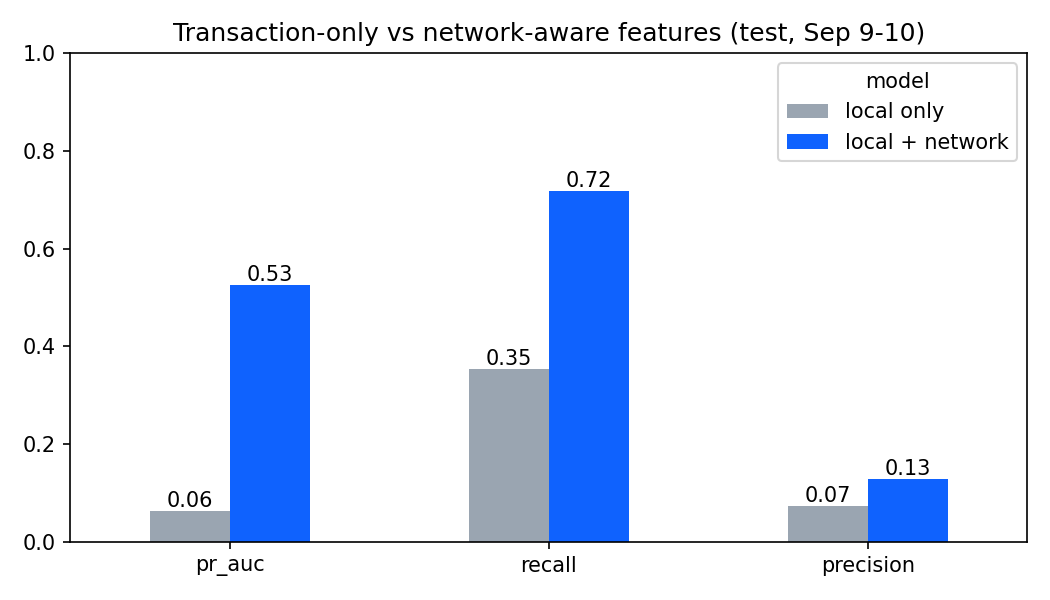

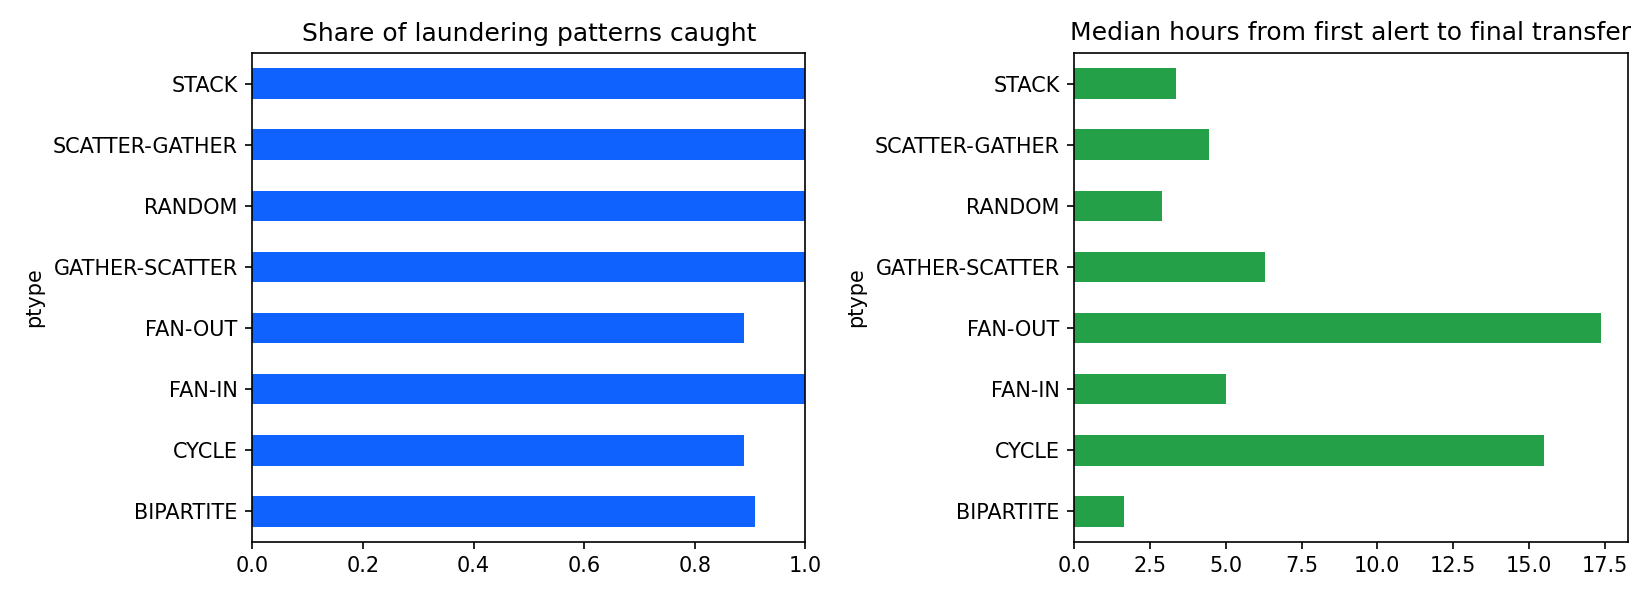

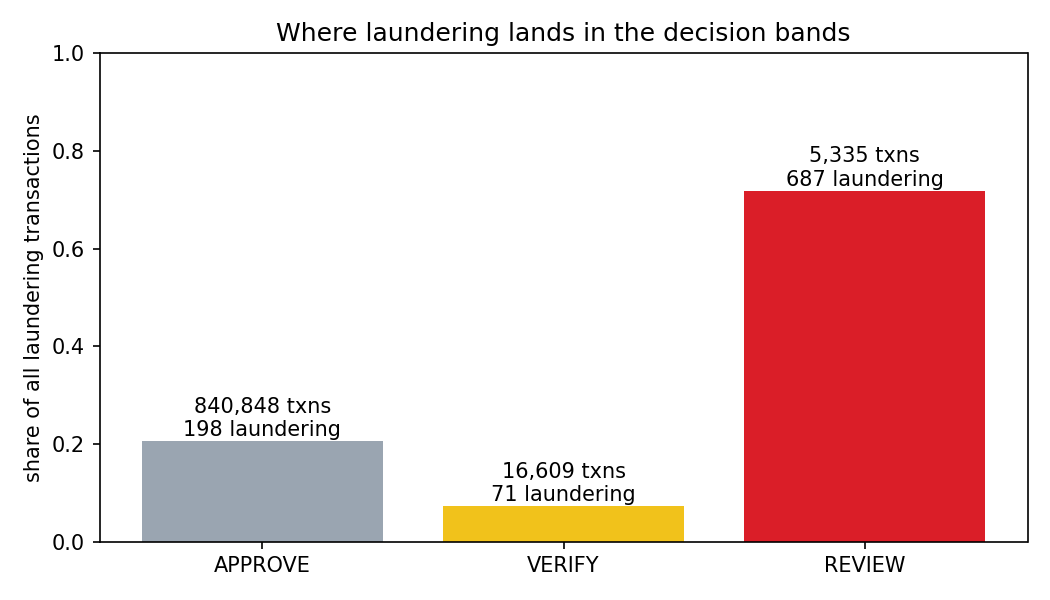

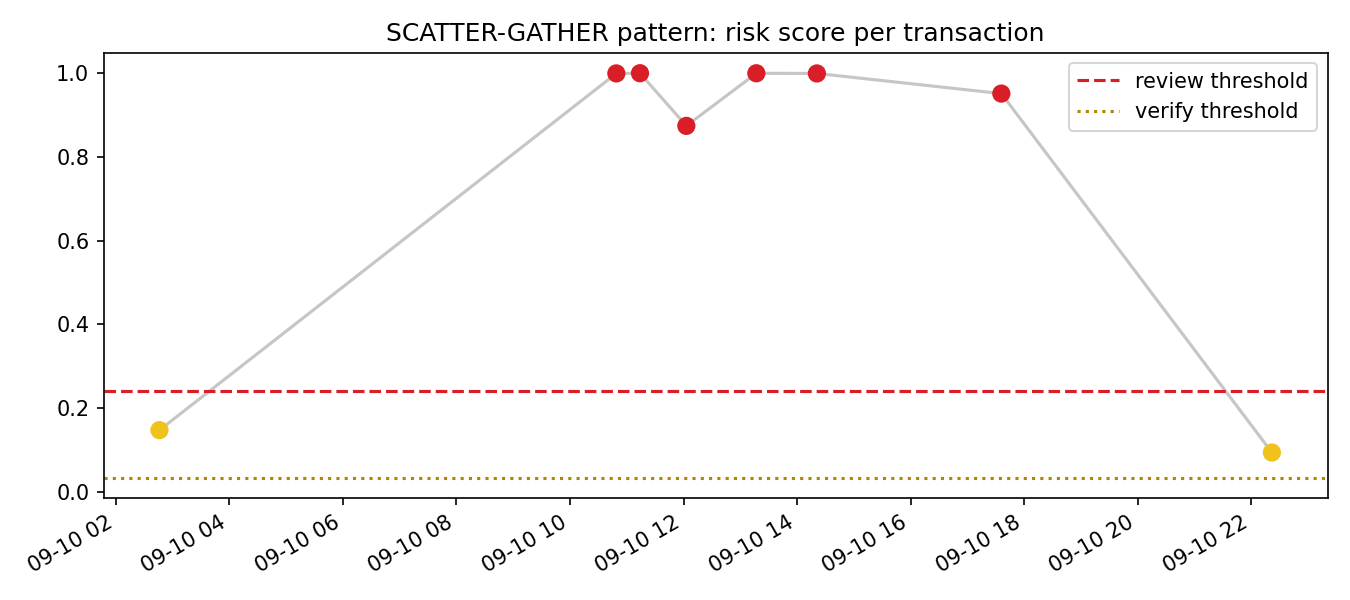

saved figures and results/metrics.json


In [29]:
import os, json
import matplotlib
matplotlib.use("Agg", force=True)          # avoid the inline backend, version-mismatched with apt matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display

FIG, RES = "/home/linux1/trustpulse/figures", "/home/linux1/trustpulse/results"
os.makedirs(FIG, exist_ok=True); os.makedirs(RES, exist_ok=True)

def save_show(fig, name):
    path = f"{FIG}/{name}"
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.close(fig)
    display(Image(path))

y = te.is_laundering.values
abl = []
for tag, (m_, f_, thr_, p_) in models.items():
    a_ = p_ >= thr_
    abl.append(dict(model=tag, pr_auc=average_precision_score(y, p_), recall=y[a_].sum() / y.sum(), precision=y[a_].mean()))
abl = pd.DataFrame(abl).set_index("model")
fig, ax = plt.subplots(figsize=(7, 4))
abl.T.plot.bar(ax=ax, rot=0, color=["#9aa5b1", "#0f62fe"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f")
ax.set_ylim(0, 1); ax.set_title("Transaction-only vs network-aware features (test, Sep 9-10)")
save_show(fig, "01_ablation.png")

lt_t = lt.groupby("ptype").agg(caught=("caught", "mean"), lead_h=("hours_before_final", "median"))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
lt_t.caught.plot.barh(ax=ax[0], color="#0f62fe"); ax[0].set_xlim(0, 1); ax[0].set_title("Share of laundering patterns caught")
lt_t.lead_h.plot.barh(ax=ax[1], color="#24a148"); ax[1].set_title("Median hours from first alert to final transfer")
save_show(fig, "02_lead_time.png")

band = d.groupby("decision").is_laundering.agg(txns="size", laundering="sum").reindex(["APPROVE", "VERIFY", "REVIEW"])
band["share_of_laundering"] = band.laundering / band.laundering.sum()
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(band.index, band.share_of_laundering, color=["#9aa5b1", "#f1c21b", "#da1e28"])
for i, (t, l) in enumerate(zip(band.txns, band.laundering)):
    ax.text(i, band.share_of_laundering.iat[i] + 0.01, f"{t:,} txns\n{l} laundering", ha="center")
ax.set_ylim(0, 1); ax.set_ylabel("share of all laundering transactions"); ax.set_title("Where laundering lands in the decision bands")
save_show(fig, "03_decision_bands.png")

dp = d[d.pattern_id == demo_pid].sort_values("txn_id")
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(dp.ts, dp.score, color="#c6c6c6", zorder=1)
ax.scatter(dp.ts, dp.score, c=dp.decision.map({"APPROVE": "#9aa5b1", "VERIFY": "#f1c21b", "REVIEW": "#da1e28"}), s=60, zorder=3)
ax.axhline(thr_review, ls="--", color="#da1e28", label="review threshold")
ax.axhline(thr_verify, ls=":", color="#b28600", label="verify threshold")
ax.set_title(f"{dp.pattern_type.iat[0]} pattern: risk score per transaction"); ax.legend(); fig.autofmt_xdate()
save_show(fig, "04_demo_pattern.png")

out = {"ablation_test": abl.round(4).to_dict(orient="index"),
       "propagation_check_test": results.round(4).to_dict(orient="index"),
       "decision_bands_test": band.astype(float).round(4).to_dict(orient="index"),
       "lead_time_by_pattern_type": lt_t.round(3).to_dict(orient="index"),
       "split": {"train": "2022-09-01..06", "val": "2022-09-07..08", "test": "2022-09-09..10"},
       "alert_budget": BUDGET}
with open(f"{RES}/metrics.json", "w") as f:
    json.dump(out, f, indent=2, default=float)
print("saved figures and results/metrics.json")

In [30]:
feats_nc = [f for f in LOCAL + NET if f not in ("fmt_code", "cur_code", "cross_currency")]
m_nc = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, max_leaf_nodes=63,
                                      early_stopping=False, class_weight="balanced", random_state=42)
m_nc.fit(trs[feats_nc], trs.is_laundering)
pv, pt_ = m_nc.predict_proba(va[feats_nc])[:, 1], m_nc.predict_proba(te[feats_nc])[:, 1]
a_ = pt_ >= np.quantile(pv, 1 - BUDGET)
print(f"network model without channel/currency: test PR-AUC {average_precision_score(y, pt_):.4f} | "
      f"recall {y[a_].sum()/y.sum():.3f} | precision {y[a_].mean():.3f}")

network model without channel/currency: test PR-AUC 0.4693 | recall 0.714 | precision 0.056


## Part 3: Real-time engine on LinuxONE

In [31]:
import sys; sys.path.insert(0, "/home/linux1/trustpulse")
from trustpulse import build
m, feats, _, _ = models["local + network"]
info = build.export_bundle(aml, m, feats, trs[feats].median(), thr_review, thr_verify,
                           stream_start="2022-09-09",
                           model_dir="/home/linux1/trustpulse/models",
                           artifact_dir="/home/linux1/trustpulse/artifacts/engine",
                           spotlight_pattern=demo_pid, pattern_starts=starts)

{
  "trees": 300,
  "nodes": 37500,
  "max_depth": 24,
  "accounts_in_state": 515088,
  "pairs_in_state": 978515,
  "history_payments": 4214445,
  "stream_payments": 862792,
  "seconds": 2.5
}


In [32]:
# Stream 20,000 test payments one at a time; compare with batch features and sklearn scores.
rep = build.parity_check("/home/linux1/trustpulse/models", "/home/linux1/trustpulse/artifacts/engine",
                         te, m, n=20000, out_path="/home/linux1/trustpulse/results/realtime_parity.json")

{
  "machine": "s390x",
  "payments": 20000,
  "feature_max_rel_diff": 4.3712369160501634e-14,
  "worst_features": {
    "src_passthrough": 0.0,
    "dst_passthrough": 0.0,
    "src_out_amt": 0.0
  },
  "score_max_abs_diff_vs_sklearn": 0.0012715920297217036,
  "decision_agreement": 1.0,
  "latency_ms": {
    "features_p50": 0.008,
    "score_and_explain_p50": 0.2445,
    "end_to_end_p50": 0.2556,
    "end_to_end_p99": 0.3948,
    "end_to_end_max": 370.8102
  },
  "throughput_payments_per_s": 3455.9
}


In [2]:
import pandas as pd
from sklearn.metrics import precision_recall_curve
d = pd.read_pickle("/home/linux1/trustpulse/artifacts/decisions_test.pkl")
prec, rec, thr_ = precision_recall_curve(d.is_laundering, d.score)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
i = f1[:-1].argmax()
print(f"best test F1 {f1[i]:.3f} at precision {prec[i]:.3f}, recall {rec[i]:.3f}, threshold {thr_[i]:.4f}")
print(f"test payments {len(d):,}, laundering {d.is_laundering.sum():,}")

best test F1 0.539 at precision 0.692, recall 0.441, threshold 0.9869
test payments 862,792, laundering 956


## Part 4: Scoring on the Telum II on-chip AI accelerator

In [2]:
# Rebuild the network features from the saved IBM AML frame (same logic as Part 2, via trustpulse.build).
import sys, gc, time, platform, numpy as np, pandas as pd
sys.path.insert(0, "/home/linux1/trustpulse")
from trustpulse.build import batch_features
from trustpulse.engine import FEATURES

t0 = time.time()
raw = pd.read_pickle("/home/linux1/trustpulse/artifacts/aml_hi_small.pkl")
raw = raw[raw.ts < "2022-09-11"].reset_index(drop=True)
fx = raw[(raw.cur_recv == "US Dollar") & (raw.cur_paid != "US Dollar")]
rate = (fx.amt_recv / fx.amt_paid).groupby(fx.cur_paid, observed=True).median()
rate["US Dollar"] = 1.0
raw["amt_usd"] = raw.cur_paid.map(rate).astype(float).fillna(1.0) * raw.amt_paid
raw["cross_currency"] = (raw.cur_recv.astype(str) != raw.cur_paid.astype(str)).astype("int8")
raw["fmt_code"] = raw.fmt.cat.codes
raw["cur_code"] = raw.cur_paid.cat.codes
raw = raw[["ts", "src", "dst", "amt_usd", "fmt_code", "cur_code", "cross_currency", "is_laundering"]]
del fx; gc.collect()

aml = batch_features(raw)
aml["ts"] = raw.ts.values
aml["is_laundering"] = raw.is_laundering.values
del raw; gc.collect()
LOCAL, NET = FEATURES[:6], FEATURES[6:]
print(f"{len(aml):,} payments, {len(FEATURES)} features in {time.time()-t0:.1f}s on {platform.machine()}")

5,077,237 payments, 27 features in 18.2s on s390x


In [4]:
# Hand the features to the standalone Snap ML benchmark (scripts/telum_benchmark.py).
FEATS = LOCAL + NET
tr = aml[aml.ts < "2022-09-07"]
va = aml[(aml.ts >= "2022-09-07") & (aml.ts < "2022-09-09")]
te = aml[aml.ts >= "2022-09-09"]
rng = np.random.default_rng(42)
trs = tr[(tr.is_laundering == 1) | (rng.random(len(tr)) < 0.2)]
np.savez("/home/linux1/trustpulse/artifacts/telum_data.npz",
         Xtr=trs[FEATS].to_numpy(np.float32), ytr=trs.is_laundering.to_numpy(),
         Xva=va[FEATS].to_numpy(np.float32), yva=va.is_laundering.to_numpy(),
         Xte=te[FEATS].to_numpy(np.float32), yte=te.is_laundering.to_numpy())
print(len(trs), len(va), len(te))

651920 965524 862792
